In [1]:
import pandas as pd
import numpy as np

In [4]:
data_df = pd.read_csv("Advertising.csv", index_col= 0)
data_df.head()

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


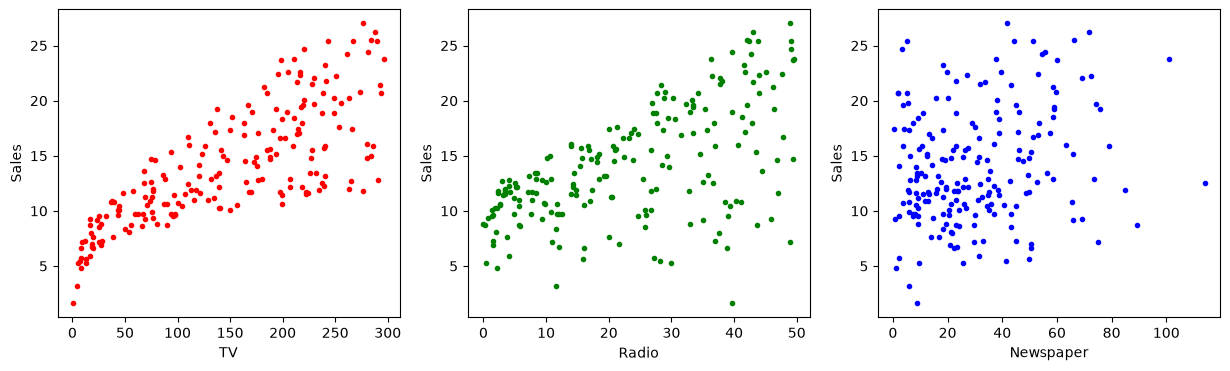

In [9]:
import matplotlib as mpl
from matplotlib import pyplot as plt

fig = plt.figure(figsize=(15,4))
gs = mpl.gridspec.GridSpec(1,3)

# Plot of sales vs TV
ax = fig.add_subplot(gs[0])
ax.scatter(data_df["TV"], data_df["Sales"], color="red", marker=".")
ax.set_xlabel("TV")
ax.set_ylabel("Sales")

# Plot of sales vs radio
ax = fig.add_subplot(gs[1])
ax.scatter(data_df["Radio"], data_df["Sales"], color="green", marker=".")
ax.set_xlabel("Radio")
ax.set_ylabel("Sales")

# Plot of sales vs newspaper
ax = fig.add_subplot(gs[2])
ax.scatter(data_df["Newspaper"], data_df["Sales"], color="blue", marker=".")
ax.set_xlabel("Newspaper")
ax.set_ylabel("Sales")

plt.show()

The first plot shows a sharp upward trend in the number of units sold as TV advertising increases. A similar trend is also found as radio advertising increases. However, in the last plot, there does not appear to be a relationship between newspaper advertising and number of units sold.

Simple Linear Function- Ordinary Least Square

From the samples provided, firest we need to find Beta 1 from the first expression and subsititute the value of Beta 1 in second expression for Beta 0.

In [10]:
X = data_df.TV.to_numpy()
Y = data_df.Sales.to_numpy()

In [11]:
#Calculating Beta 1
x_mean = X.mean()
y_mean = Y.mean()

beta_1 = np.sum((X - x_mean) * (Y - y_mean)) / np.sum(np.power((X - x_mean), 2))
print(beta_1)

0.047536640433019736


In [13]:
#Calculating Beta 0
beta_0 = y_mean - (beta_1 * x_mean)
beta_0

np.float64(7.0325935491276965)

In [14]:
#Best Fit Line Equation

print(f"y = {beta_0: .3f} + {beta_1: .3f}x")

y =  7.033 +  0.048x


In [15]:
#Calculating SSE
y_hat = beta_0 + (beta_1 * X)
SSE = np.sum((Y - y_hat) ** 2)
print(SSE)

2102.5305831313512


#### SKLearn Implementation

In [20]:
from sklearn.linear_model import LinearRegression

In [21]:
linear_reg = LinearRegression()

In [22]:
linear_reg.fit(X.reshape(-1, 1), Y.reshape(-1, 1))

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.05]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[7.03]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[1211.12]


In [23]:
#Beta_0
linear_reg.intercept_

array([7.03259355])

In [24]:
#Beta_1
linear_reg.coef_

array([[0.04753664]])

In [35]:
y_cap = linear_reg.predict(X.reshape(-1,1))

In [34]:
SSE = np.sum(np.power((Y - y_cap.flatten()), 2))
print(SSE)

2102.5305831313512
